In [2]:
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
import numpy as np

# Paths
base_dir   = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
data_path  = base_dir / "Data"
num_file = data_path / "Numerical/simulation_data.h5"
ana_file = data_path / "Analytical/simulation_data.h5"

# Load
with h5py.File(num_file, "r") as f_num, h5py.File(ana_file, "r") as f_ana:
    x_num = f_num["x"][:]
    t_num = f_num["times"][:]
    E_num = f_num["energies"][:]

    x_ana = f_ana["x"][:]
    t_ana = f_ana["times"][:]
    E_ana = f_ana["energies"][:]

    psi_num = f_num["psi_prob"][:]   # shape (n_states, n_steps, N)
    psi_ana = f_ana["psi_prob"][:]

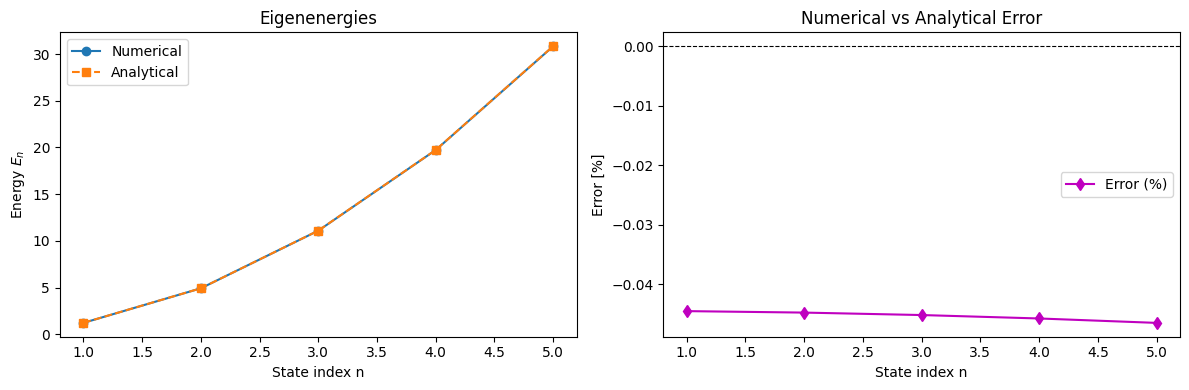

In [3]:
# --- Percentage error ---
error_percent = 100 * (E_num - E_ana) / E_ana

# --- Two plots side by side ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left plot: Energies
axes[0].plot(range(1, len(E_num)+1), E_num, 'o-', label="Numerical")
axes[0].plot(range(1, len(E_ana)+1), E_ana, 's--', label="Analytical")
axes[0].set_xlabel("State index n")
axes[0].set_ylabel("Energy $E_n$")
axes[0].set_title("Eigenenergies")
axes[0].legend()

# Right plot: Error %
axes[1].plot(range(1, len(error_percent)+1), error_percent, 'd-m', label="Error (%)")
axes[1].axhline(0, color='k', linestyle='--', linewidth=0.8)
axes[1].set_xlabel("State index n")
axes[1].set_ylabel("Error [%]")
axes[1].set_title("Numerical vs Analytical Error")
axes[1].legend()

# Layout + Save
plt.tight_layout()
plt.savefig(
    'Figs/Eigenenergies_with_Error.png',
    dpi=300,
    format='png',
    facecolor='white',
    edgecolor='black',
    transparent=True
)
plt.show()

In [4]:
# ==============================
# PLOT SNAPSHOT FROM HDF5
# ==============================
import h5py
import matplotlib.pyplot as plt

def plot_snapshot(file_path, state=0, time_index=0, analytical=None):
    """
    Plot numerical (and optionally analytical) probability density at a given time.

    Parameters
    ----------
    file_path   : str
        or Path to .h5 file (master or per-state file).
    state       : int
        State index (ignored if per-state file).
    time_index  : int
        Time snapshot index.
    analytical  : tuple (x_ana, psi_ana) or None
        Analytical solution to overlay, shape psi_ana[time, x].
    """
    with h5py.File(file_path, "r") as f:
        x = f["x"][:]
        times = f["times"][:]

        # master file case
        if "psi_prob" in f and f["psi_prob"].ndim == 3:
            psi_prob = f["psi_prob"][state, :, :]
            energy = f["energies"][state]
        # per-state file case
        else:
            psi_prob = f["psi_prob"][:]
            energy = f["energy"][()]

        psi_snapshot = psi_prob[time_index, :]

    # --- Plot ---
    plt.figure(figsize=(7,4))
    plt.plot(x, psi_snapshot, label=f"Numerical (E={energy:.3f})")

    if analytical is not None:
        x_ana, psi_ana = analytical
        plt.plot(x_ana, psi_ana[time_index, :], '--', label="Analytical")

    plt.xlabel("x")
    plt.ylabel(r"$|\psi(x,t)|^2$")
    plt.title(f"t = {times[time_index]:.2f}")
    plt.legend()
    plt.savefig(
    'Figs/ProbabilityDensities.png',
    dpi=300,                      # High resolution
    format='png',                # File format
    facecolor='white',           # Background color of the figure
    edgecolor='black',           # Border color
    transparent=True,           # Set to True for transparent background
    )
    plt.show()

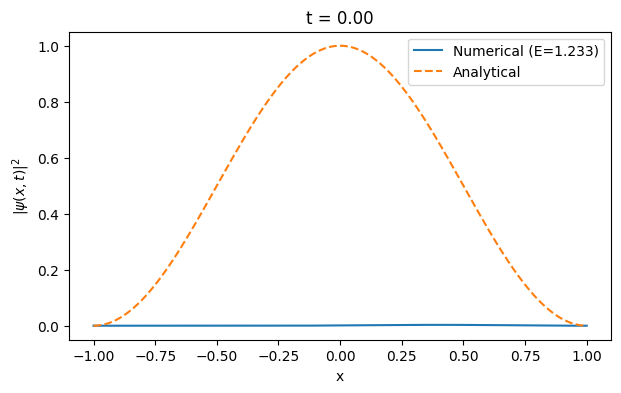

In [5]:
# Suppose you already computed analytical (x_ana, psi_ana)
plot_snapshot("Data/Numerical/simulation_data.h5",
              state=0, time_index=000,
              analytical=(x_ana, psi_ana[0]))


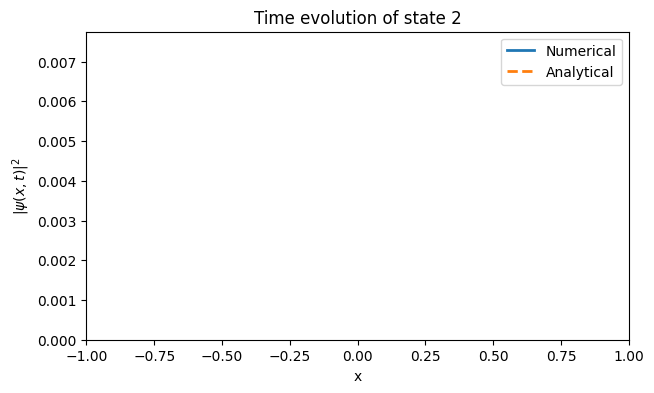

In [58]:
xmin, xmax = -1.0, 1.0

state = 1   # first excited
fig, ax = plt.subplots(figsize=(7,4))

line_num, = ax.plot([], [], lw=2, label="Numerical")
line_ana, = ax.plot([], [], '--', lw=2, label="Analytical")
ax.set_xlim(xmin, xmax)
ax.set_ylim(0, 2.5*np.max(psi_num[state,:,:]))
ax.set_xlabel("x")
ax.set_ylabel(r"$|\psi(x,t)|^2$")
ax.set_title(f"Time evolution of state {state+1}")
ax.legend()

def init():
    line_num.set_data([], [])
    line_ana.set_data([], [])
    return line_num, line_ana

def update(frame):
    line_num.set_data(x_num, psi_num[state, frame, :])
    line_ana.set_data(x_ana, psi_ana[state, frame, :])
    ax.set_title(f"State {state+1}, t={t_num[frame]:.2f}")
    return line_num, line_ana

ani = FuncAnimation(fig, update, frames=len(t_num), init_func=init,
                    interval=30, blit=True)

plt.show()